# Stratified Cross-Validation

This notebook compares `StratifiedKFold` with plain `KFold` on an imbalanced dataset, showing how stratification keeps the class proportions stable across folds and yields more reliable scores.

## Import Required Libraries

Import the generators, splitters and model utilities.

In [1]:
# Import the required libraries.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    KFold, StratifiedKFold, RepeatedStratifiedKFold,
    GroupKFold, cross_val_score
)

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## Create an Imbalanced Dataset

Generate a binary problem where the positive class is only about 10 percent of the samples.

In [2]:
# Generate an imbalanced binary classification dataset.
X, y = make_classification(
    n_samples=500, n_features=10, n_informative=5,
    weights=[0.9, 0.1], random_state=42
)
print(f"Class counts: {np.bincount(y)}.")
print(f"Positive rate: {y.mean():.3f}.")

Class counts: [448  52].
Positive rate: 0.104.


## Class Proportion per Fold

Compute the fraction of the minority class in each validation fold for both plain and stratified k-fold.

In [3]:
# Compute the minority-class proportion per validation fold.
n_splits = 5
plain = KFold(n_splits=n_splits, shuffle=True, random_state=42)
strat = StratifiedKFold(n_splits=n_splits, shuffle=True,
                        random_state=42)

plain_props = [y[val].mean() for _, val in plain.split(X, y)]
strat_props = [y[val].mean() for _, val in strat.split(X, y)]

print(f"KFold props:      {np.round(plain_props, 3)}.")
print(f"StratifiedKFold:  {np.round(strat_props, 3)}.")

KFold props:      [0.11 0.08 0.07 0.11 0.15].
StratifiedKFold:  [0.1  0.1  0.1  0.11 0.11].


## Visualise the Proportions

Plot the minority-class fraction per fold; stratification keeps it close to the overall rate shown as a dashed line.

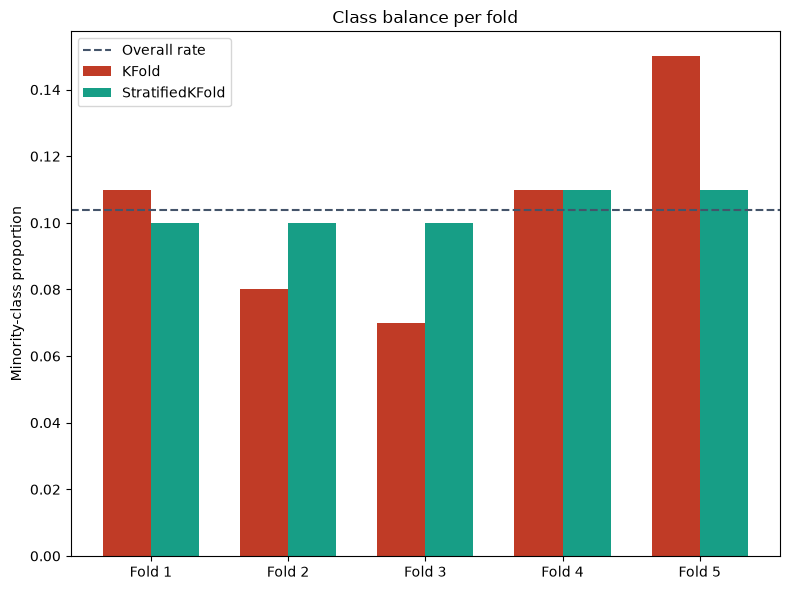

In [4]:
# Plot the minority-class proportion per fold.
fig, ax = plt.subplots(figsize=(8, 6))
x_pos = np.arange(n_splits)
width = 0.35
ax.bar(x_pos - width / 2, plain_props, width,
       color=colors[3], label="KFold")
ax.bar(x_pos + width / 2, strat_props, width,
       color=colors[0], label="StratifiedKFold")
ax.axhline(y.mean(), color=colors[4], linestyle="--",
           label="Overall rate")
ax.set_xticks(x_pos)
ax.set_xticklabels([f"Fold {i + 1}" for i in range(n_splits)])
ax.set_ylabel("Minority-class proportion")
ax.set_title("Class balance per fold")
ax.legend()
plt.tight_layout()
plt.show()

## Compare the Score Estimates

Cross-validate the same model with each strategy using the F1 score, which is sensitive to the minority class.

In [5]:
# Compare score estimates from both strategies.
model = LogisticRegression(max_iter=5000)
plain_f1 = cross_val_score(model, X, y, cv=plain, scoring="f1")
strat_f1 = cross_val_score(model, X, y, cv=strat, scoring="f1")

print(f"KFold F1:      {plain_f1.mean():.4f} "
      f"(+/- {plain_f1.std():.4f}).")
print(f"Stratified F1: {strat_f1.mean():.4f} "
      f"(+/- {strat_f1.std():.4f}).")

KFold F1:      0.6417 (+/- 0.1278).
Stratified F1: 0.7236 (+/- 0.0648).


## Repeated Stratified k-Fold

`RepeatedStratifiedKFold` repeats the stratified split several times with different shuffles to further reduce estimate variance.

In [6]:
# Reduce variance with repeated stratified k-fold.
rskf = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=42
)
rep_f1 = cross_val_score(model, X, y, cv=rskf, scoring="f1")
print(f"Repeated stratified F1: {rep_f1.mean():.4f} "
      f"(+/- {rep_f1.std():.4f}) over {len(rep_f1)} fits.")

Repeated stratified F1: 0.6966 (+/- 0.0889) over 15 fits.


## Grouped Cross-Validation

When samples belong to groups (e.g. the same patient), `GroupKFold` keeps a group entirely within one fold to avoid leakage. Here we assign synthetic groups.

In [7]:
# Demonstrate GroupKFold with synthetic groups.
groups = np.random.randint(0, 20, size=len(y))
gkf = GroupKFold(n_splits=5)
group_f1 = cross_val_score(
    model, X, y, cv=gkf, groups=groups, scoring="f1"
)
print(f"GroupKFold F1: {group_f1.mean():.4f} "
      f"(+/- {group_f1.std():.4f}).")
for fold, (_, val) in enumerate(gkf.split(X, y, groups)):
    n_groups = len(np.unique(groups[val]))
    print(f"Fold {fold + 1}: {n_groups} distinct groups.")

GroupKFold F1: 0.6758 (+/- 0.1442).
Fold 1: 4 distinct groups.
Fold 2: 4 distinct groups.
Fold 3: 4 distinct groups.
Fold 4: 4 distinct groups.
Fold 5: 4 distinct groups.


## Summary

- **Stratification**: `StratifiedKFold` preserves the class proportions in every fold, essential for imbalanced data.
- **Plain KFold**: can produce folds with too few minority samples, giving noisy and biased score estimates.
- **RepeatedStratifiedKFold**: averages over several stratified repetitions to shrink the variance of the estimate.
- **GroupKFold**: keeps each group in a single fold to prevent leakage when samples are not independent.